<a href="https://colab.research.google.com/github/slover1126/slover1126/blob/main/%ED%95%B8%EC%A6%88%EC%98%A8_%EB%A8%B8%EC%8B%A0%EB%9F%AC%EB%8B%9D_9%EC%9E%A5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**9장 비지도 학습**


*   **비지도 학습**은 입력(X)만 있고 레이블(Y)이 없는 문제를 해결하는 방법임
*   다음과 같은 비지도 학습을 본 장에서 다룸
    *   군집(비슷한 샘플을 클러스터로 모음)
    *   이상치 탐지(정상 데이터가 어떻게 보이는지를 학습하고 이상치를 감지)
    *   밀도 추정(데이터셋 생성 확률 과정(random process)의 **확률 밀도 함수(probability density function,PDF)** 를 추정함)


**9.1 군집**



*   **군집** 은 비슷한 샘플끼리 뭉쳐놓은 것으로, 하나의 군집을 **클러스터** 라고 함
*   군집은 고객분류 및 기타 여러 분야에서 사용됨



**9.1.1 $k$-평균**


*   **$k$-평균** 알고리즘은 센트로이드(클러스터의 중심점)를 통해 각 샘플을 클러스터에 할당할 수 있는 방법임(자세한 알고리즘은 뒤에서 서술),K는 클러스터의 수를 의미함
*   **로이드-포지 알고리즘** 이라고도 함

In [2]:
#k-means 코드
from sklearn.cluster import KMeans
import numpy as np
from sklearn.datasets import make_blobs

blob_centers = np.array([
    [ 0.2,  2.3],
    [-1.5,  2.3],
    [-2.8,  1.8],
    [-2.8,  2.8],
    [-2.8,  1.3]
])
blob_std = np.array([0.4, 0.3, 0.1, 0.1, 0.1])
k=5
X, y = make_blobs(n_samples=2000, centers=blob_centers, cluster_std=blob_std, random_state=7)
kmeans  = KMeans(n_clusters=k, random_state=42, n_init = 10)
y_pred = kmeans.fit_predict(X) #X를 바로 예측함

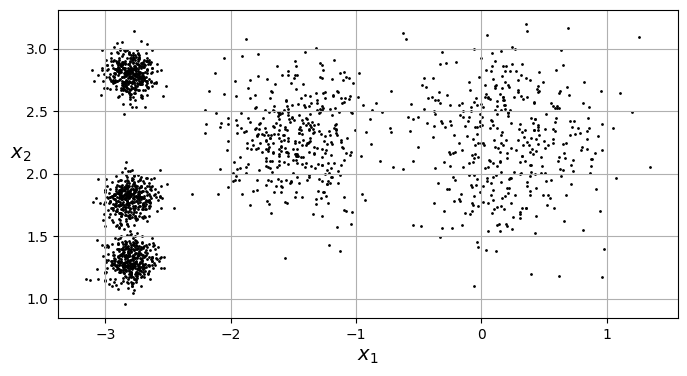

In [3]:
#생성한 데이터 시각화
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.scatter(X[:, 0], X[:, 1], c="black", s=1)
plt.xlabel("$x_1$", fontsize=14)
plt.ylabel("$x_2$", fontsize=14, rotation=0)
plt.grid(True)
plt.show()

In [4]:
#샘플은 5개의 클러스터 중 하나에 할당되며 군집에서 각 샘플의 레이블은 알고리즘이 샘플에 할당한 클래스를 의미함
#KMeans는 변수명.labels_를 통해 예측 레이블 확인 가능

print(y_pred)

print(y_pred is kmeans.labels_)
#True이므로 두 객체가 같음을 확인 가능

[0 0 4 ... 3 1 0]
True


In [5]:
#이 알고리즘이 찾은 센트로이드 5개를 확인
kmeans.cluster_centers_

array([[-2.80214068,  1.55162671],
       [ 0.08703534,  2.58438091],
       [-1.46869323,  2.28214236],
       [-2.79290307,  2.79641063],
       [ 0.31332823,  1.96822352]])

In [6]:
#새로운 샘플에 가장 가까운 센트로이드의 클러스터를 할당하기
X_new = np.array([[0,2], [3,2], [3,3],[-3,2.5]])
kmeans.predict(X_new)
#각각 4번, 4번, 3번, 3번 클러스터로 할당되었음을 의미함

array([4, 4, 4, 3], dtype=int32)

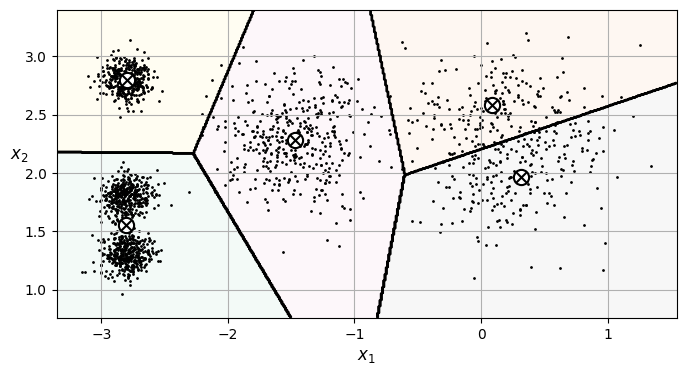

In [7]:
#클러스터의 결정 경계를 보르노이 다이어그램(평면을 특정 점까지의 거리가 가장 가까운 점의 집합으로 분할한 그림)으로 표시하기

# 1. 보로노이 결정 경계 및 센트로이드 시각화 함수
def plot_decision_boundaries(clusterer, X):
    # 그리드 좌표 생성
    x_min, x_max = X[:, 0].min() - 0.2, X[:, 0].max() + 0.2
    y_min, y_max = X[:, 1].min() - 0.2, X[:, 1].max() + 0.2
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500),
                         np.linspace(y_min, y_max, 500))

    # 각 그리드 점의 클러스터 예측
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # 결정 경계선 (보로노이 다이어그램 실선)
    plt.contour(xx, yy, Z, colors='k', linewidths=1.5)
    # 영역 색칠 (선택 사항)
    plt.contourf(xx, yy, Z, alpha=0.15, cmap="Pastel2")

    # 원본 데이터 점
    plt.scatter(X[:, 0], X[:, 1], c='black', s=1)

    # 센트로이드 표시 (흰색 원 + 검은색 X)
    centroids = clusterer.cluster_centers_
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=120, color='white', edgecolors='black', linewidths=1.5, zorder=10)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=60, color='black', linewidths=1.5, zorder=11)

    plt.xlabel("$x_1$", fontsize=12)
    plt.ylabel("$x_2$", fontsize=12, rotation=0)

# 2. 출력
plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans, X)
plt.grid(True)
plt.show()



*   k-평균은 클러스터의 크기가 많이 다르면 잘 작동하지 않음(클러스터에 할당할 때 센트로이드까지의 거리만을 고려하므로)
*   샘플을 하나의 클러스터에 바로 넣는 **하드 군집(hard clustering)** 보다 샘플에 점수를 부여하는 **소프트 군집(soft clustering)** 이 유용할 수 있으며 이때 점수는 모든 센트로이드까지의 거리나 가우스 방사기저 함수같은 유사도 점수를 사용할 수 있음



In [8]:
# .transform을 통해 각 센트로이드 까지의 거리를 계산한 값을 반환할 수 있음
kmeans.transform(X_new).round(2)
# 첫번째 샘플의 경우 0번 센트로이드와는 2.84, 1번 센트로이드와는 0.59 만큼 떨어져 있다고 해석할 수 있음

array([[2.84, 0.59, 1.5 , 2.9 , 0.31],
       [5.82, 2.97, 4.48, 5.85, 2.69],
       [5.98, 2.94, 4.53, 5.8 , 2.88],
       [0.97, 3.09, 1.55, 0.36, 3.36]])

**K-평균 알고리즘**



1.   레이블이나 센트로이드가 주어지지 않은경우, **랜덤하게 K개의 샘플을 뽑아 그 위치를 센트로이드로 사용**
2.  센트로이드를 통해 각 샘플에 클러스터를 할당함
3.  그 다음 각 클러스터에 속한 좌표들의 평균으로 센트로이드를 이동시킴
4.  다시 레이블 할당(2번 과정 반복)
5.  클러스터 안에 있는 좌표들의 평균으로 센트로이드를 이동시킴(3번 과정 반복)
6.  반복

*   알고리즘이 최소화 하고자 하는 값은 **이너셔(inerita)** 로, k-means의 평가 지표이고, 뒤에서 더 설명함
*   이  알고리즘은 제한된 횟수 안에서 수렴하는 것을 보장함(샘플과 가장 가까운 센트로이드 사이의 평균 제곱 거리는 감소만 하고 음수가 될 수 없으므로)


*   다만 수렴은 보장되지만 운이 없다면 랜덤 초기화 단계에 잘못 설정되면 지역 최솟값으로 수렴할 수 있는 문제가 있음  







**센트로이드 초기화 방법**


*   센트로이드 위치를 근사하게 알 수 있다면 **init 하이퍼파라미터에 센트로이드를 담은 넘파이 배열을 지정하고 n_init = 1 로 설정하면 됨**


In [9]:
#센트로이드를 직접 지정
good_init = np.array([[-3,3], [-3,2],[-3,1],[-1,2],[0,2]])
kmeans = KMeans(n_clusters=5, init=good_init , n_init=1, random_state=42)
kmeans.fit(X)

KMeans(init=array([[-3,  3],
       [-3,  2],
       [-3,  1],
       [-1,  2],
       [ 0,  2]]),
       n_clusters=5, n_init=1, random_state=42)



*   또 다른 방법으로는 알고리즘 자체를 여러번 시행하고, 가장 좋은 센트로이드를 선택하는 방법임
*   **알고리즘의 반복 횟수는 n_init 하이퍼파라미터로 지정함**

*   이때, 최적의 센트로이드를 선택하는 기준이 **각 샘플과 가장 가까운 센트로이드 사이의 제곱 거리 합**인 **이너셔(inertia)** 임 (이너셔가 낮을수록 잘 클러스터링된 것임)
*   KMeans 알고리즘에서 n_init을 지정하면 그 수만큼 반복한 후 이너셔가 가장 낮은 모델을 반환함







In [10]:
#이너셔를 확인하려면 변수명.inertia_ 로 확인하면 됨
kmeans.inertia_

211.59853725816828

In [11]:
# 변수명.scores()는 음숫값을 반환(score()함수는 가장 큰 값을 반환하는 규칙 떄문에 음수를 붙여서 반환시킴)
kmeans.score(X)
#-211.59853725816828 로 음수가 붙어서 나옴

-211.59853725816828

**K-평균++ 알고리즘**


*   적절한 센트로이드를 선택하기 위해 제시된 방법으로, 다른 센트로이드와 거리가 먼 센트로이드를 선택하는 방식을 이용
*   최적이 아닌 솔루션으로 수렴할 가능성을 크게 낮춤



*   알고리즘은 다음과 같이 진행

    1.   첫번째 센트로이드를 샘플에서 무작위로 선택
    2.   다음 센트로이드를 거리의 제곱의 확률에 비례하게 선택
$$P(\mathbf{x}^{(i)}) = \frac{D(\mathbf{x}^{(i)})^2}{\sum_{j=1}^{m} D(\mathbf{x}^{(j)})^2}$$

* $P(\mathbf{x}^{(i)})$ 는 $i$번째 샘플이 센트로이드로 선택될 확률
*   $D(\mathbf{x})$는 가장 가까운 센트로이드 까지의 거리를 의미
* 즉, 센트로이드가 가까이에 있을 경우 센트로이드 주위의 점이 새로운 센트로이드로 선택될 확률을 낮춰줌
    
    3.이러한 방식을 통해 $k$개의 센트로이드를 처음으로 지정함



*   kmeans 클래스는 기본적으로 이 초기화 방법을 사용함




**$k$-평균 속도 개선과 미니배치 $k$-평균**


*   **algorithm = "elkan"** 으로 설정하면 엘칸이 제시한 삼각부등식을 활용하여 셈플과 센트로이드 간의 거리의 상한선과 하한선을 유지하는 방식이 쓸 수 있음
*   불필요한 거리 계산을 줄이는 방식인데, 항상 시간을 줄이는건 아니고 떄로는 훈련속도가 상당히 느려질 수 있음

*   전체 데이터셋을 보지 않고 센트로이드 이동 시 마다 미니배치만을 이용하여 센트로이드를 이동시키는 방법도 사용할 수 있음
*   알고리즘 속도를 3배,4배 정도 향상시킬 수 있고 메모리에 들어가지 않는 대량의 데이터셋을 다루는데 적합함



In [13]:
#사이킷런은 MiniBatchKMeans 라는 클래스에 미니배치 k-평균이 있음
from sklearn.cluster import MiniBatchKMeans

minibatch_kmeans = MiniBatchKMeans(n_clusters=5, random_state=42, n_init=3)
minibatch_kmeans.fit(X)

MiniBatchKMeans(n_clusters=5, n_init=3, random_state=42)



*   메모리에 데이터셋이 들어가지 않는 경우 memmap 클래스를 이용하거나 MiniBatchKMeans의 **partial_fit()** 을 이용하여 한번에 하나의 미니배치를 전달할 수도 있음
*   미니배치 방식이 일반적인 방식보다 속도는 빠르지만 이너셔가 조금 나쁜 단점이 있음



**최적의 클러스터 찾기**


*   클러스터를 임의로 정할 수 없는 경우 여러가지 방법을 통해서 적절한 클러스터를 찾을 수 있음
*   **엘보(elbow) 방식** 과 **실루엣 점수**를 통해 적절한 클러스터를 정할 수 있음



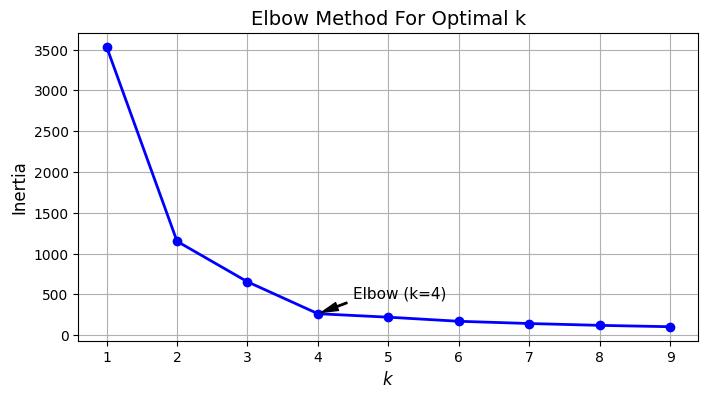

In [14]:
#엘보 그래프
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. k 값의 범위 설정 (1부터 9까지) 및 이너셔(Inertia) 수집
k_range = range(1, 10)
kmeans_per_k = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X) for k in k_range]
inertias = [model.inertia_ for model in kmeans_per_k]

# 2. 엘보 그래프 시각화
plt.figure(figsize=(8, 4))
plt.plot(k_range, inertias, "bo-", linewidth=2, markersize=6)
plt.xlabel("$k$", fontsize=12)
plt.ylabel("Inertia", fontsize=12)
plt.title("Elbow Method For Optimal k", fontsize=14)
plt.xticks(list(k_range))
plt.grid(True)

# 엘보 지점(기울기가 급격히 꺾이는 k=4 위치) 화살표 표시
plt.annotate(
    "Elbow (k=4)",
    xy=(4, inertias[3]),
    xytext=(4.5, inertias[3] + 200),
    arrowprops=dict(facecolor="black", shrink=0.1, width=1, headwidth=6),
    fontsize=11
)

plt.show()
#클러스터 수에 대해서 이너셔의 감소가 완만해지는 구간을 엘보로 정의하고 이때의 k값을 이용하는 방식
#본 그래프에선 k=4가 적절해보임

**실루엣 계수**


*   엘보 방식은 클러스터 선택이 애매하다는 단점이 있음(어디를 엘보로 놓을지 주관이 들어감)
*   따라서 **실루엣 점수(silhouette score)**       

